## 0. Импортируем библиотеки, загружаем данные

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns

In [2]:
df = pd.read_csv('../data/processed.csv')

In [3]:
np.random.seed(42)

## 1. Извлекаем реальную сумму кредита из логарифма

In [4]:
real_loan_amount = np.exp(df.loan_amount_rub)
real_employees = np.round(np.exp(df.employees_count)).astype(int)

## 2. Генерируем данные с учетом логики и корреляций

#### 2.1 ЕГРЮЛ/ЕГРИП

Возраст бизнеса связан со статусом кредита напрямую: чем моложе бизнес, тем выше риск дефолта

In [5]:
df['business_age_months'] = np.where(
    df.loan_status == 1,
    np.random.randint(36, 240, size=len(df)), # успешные от 3 до 20 лет
    np.random.randint(6, 48, size=len(df)) # дефолтные от 6 мес до 4 лет
)

Категория риска по ОКВЭД: 1 - низкий, 2 - средний, 3 - высокий

In [6]:
df['okved_risk_level'] = np.random.choice([1, 2, 3], size=len(df), p=[0.6, 0.3, 0.1])

Уставный капитал (только для ЮЛ, т.е. `business_type == 1`, у ИП уставного капитала нету → 0)

In [7]:
df['authorized_capital'] = np.where(
    df.business_type == 1,
    np.random.choice([10000, 50000, 100000, 500000], size=len(df), p=[0.5, 0.3, 0.1, 0.1]), 0
)

#### 2.2 ФНС

Выручку за прошлый год логично привязать к размеру кредита и числу сотрудников (вырчка обычно в 1.5 -5 раз больше взятого кредита)

In [8]:
df['revenue_last_year'] = real_loan_amount * np.random.uniform(1.5, 5.0, size=len(df))

Тем роста выручки (в процентах) у дефолтных кампаний чаще падает

In [9]:
df['revenue_growth_rate'] = np.where(
    df['loan_status'] == 1,
    np.random.uniform(-5.0, 30.0, size=len(df)),
    np.random.uniform(-40.0, 5.0, size=len(df))
)

Чистая прибыль (в процентах от выручки) обычно 5-25%, у дефолтных кампаний ниже

In [10]:
margin_coef = np.where(df['loan_status'] == 1, np.random.uniform(0.05, 0.25, size=len(df)), np.random.uniform(-0.15, 0.05, size=len(df)))
df['net_profit'] = df['revenue_last_year'] * margin_coef

У дефолтных кампаний вероятность недоимок по налогом обычно выше, чем у тех, кто выплатил кредит

In [11]:
df['has_tax_arrears'] = np.where(
    df['loan_status'] == 1,
    np.random.choice([0, 1], size=len(df), p=[0.95, 0.05]),
    np.random.choice([0, 1], size=len(df), p=[0.40, 0.60])
)

Аналогично с блокировкой счетов

In [12]:
df['has_blocked_accounts'] = np.where(
    df['loan_status'] == 1,
    np.random.choice([0, 1], size=len(df), p=[0.92, 0.08]),
    np.random.choice([0, 1], size=len(df), p=[0.30, 0.70])
)

#### 2.3 БКИ

Скоринг БКИ (300-850) у надеждных заемщиков выше

In [13]:
df['bki_score'] = np.where(
    df['loan_status'] == 1,
    np.random.randint(650, 850, size=len(df)),
    np.random.randint(300, 649, size=len(df))
)

Текущая долговая нагрузка связана с годовой выручкой (например, от 10 до 80% выручки)

In [14]:
df['current_debt_load'] = df['revenue_last_year'] * np.random.uniform(0.1, 0.8, size=len(df))

Максимальная просрочка в днях

In [15]:
df['max_delinquency_days'] = np.where(
    df['loan_status'] == 1,
    np.random.choice([0, 1, 5, 30], size=len(df), p=[0.7, 0.15, 0.1, 0.05]), # редкие мелкие просрочки
    np.random.randint(31, 360, size=len(df)) # длительные просрочки у дефолтных
)

Количество действующих кредитов

In [16]:
df['active_credits_count'] = np.random.randint(0, 5, size=len(df))

#### 2.4 ФССП / Арбитраж

Сумма задолженности по ФССП у дефолтных кампаний выше

In [17]:
df['fssp_debt_amount'] = np.where(
    df['loan_status'] == 1,
    np.random.choice([0, 5000, 50000], size=len(df), p=[0.85, 0.10, 0.05]),
    df['revenue_last_year'] * np.random.uniform(0.05, 0.3, size=len(df)) # до 30% от выручки съедают долги
)

Количество судебных дел

In [28]:
df['active_lawsuits_count'] = np.where(
    df['loan_status'] == 1,
    np.random.choice([0, 1, 2], size=len(df), p=[0.8, 0.15, 0.05]),
    np.random.randint(1, 8, size=len(df))
)

#### 2.5 Округлим денежные значения для красоты

In [30]:
money_cols = ['revenue_last_year', 'net_profit', 'current_debt_load', 'fssp_debt_amount']
df[money_cols] = df[money_cols].round(2)

#### 2.6 Цели кредита

1 - оборотные средства, 2 - инвестиции, 3 - рефинансирование, 4 - исполнение контрактов, 5 - рискованные цели.

In [18]:
purposes = ['working_capital', 'investment', 'refinancing', 'contract', 'risky']

df['loan_purpose'] = np.where(
    df['loan_status'] == 1,
    np.random.choice(purposes, size=len(df), p=[0.50, 0.20, 0.08, 0.17, 0.05]),
    np.random.choice(purposes, size=len(df), p=[0.35, 0.15, 0.20, 0.03, 0.27])
)

#### 2.7 Структура владения

Категории структуры владения: 1 — одиночная МСБ, 2 — взаимосвязанная МСБ. У взаимосвязанной выше шанс ододрения кредита)

In [21]:
df['ownership_structure'] = np.where(
    df['loan_status'] == 1,
    np.random.choice([1,2], size=len(df), p=[0.40, 0.60]),
    np.random.choice([1,2], size=len(df), p=[0.75, 0.25])
)

#### 2.8 Масштаб бизнеса

Уже есть признак `real_employees` отталкиваемся от него. Берём официальные границы МСБ по числу сотрудников: микро до 15, малый от 16 до 100, средний от 101 до 250

In [22]:
df['business_scale'] = np.select(
    [real_employees <= 15, real_employees <= 100],
    [1, 2],
    default=3
)

## 3. Посмотрим на созданные данные

In [23]:
df

,Unnamed: 0,loan_term_months,employees_count,business_type,is_rev_line_of_loan,loan_amount_rub,loan_status,is_franchise,industry_sector,business_age_months,...,has_blocked_accounts,bki_score,current_debt_load,max_delinquency_days,active_credits_count,fssp_debt_amount,active_lawsuits_count,loan_purpose,ownership_structure,business_scale
0,0,84,1.609438,2,0,15.408819,1,0,45,138,...,0,782,6.999399e+06,0,4,0.000000e+00,0,working_capital,2,1
1,1,60,1.098612,2,0,15.003354,1,0,72,215,...,0,800,2.626400e+06,0,1,5.000000e+03,0,investment,1,1
2,2,180,2.079442,1,0,16.973957,1,0,62,128,...,0,724,5.968333e+07,0,2,0.000000e+00,0,working_capital,2,1
3,3,60,1.098612,1,0,14.869823,1,0,unknown,50,...,0,833,4.564599e+06,0,1,0.000000e+00,2,working_capital,2,1
4,4,240,2.708050,1,0,16.748197,1,0,unknown,142,...,1,672,2.465180e+07,0,0,0.000000e+00,0,working_capital,2,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
871002,871002,60,1.945910,1,0,15.562970,1,0,45,179,...,0,709,2.319041e+06,1,2,0.000000e+00,0,working_capital,1,1
871003,871003,60,1.945910,1,1,15.757126,1,0,45,184,...,0,700,2.760720e+06,0,3,0.000000e+00,0,working_capital,2,1
871004,871004,108,3.295837,1,0,17.018257,1,0,33,132,...,0,819,9.099252e+06,0,3,0.000000e+00,1,working_capital,1,2
871005,871005,60,1.945910,1,0,15.631963,0,0,unknown,44,...,1,427,1.076349e+07,197,4,2.910133e+06,6,working_capital,1,1


<Axes: >

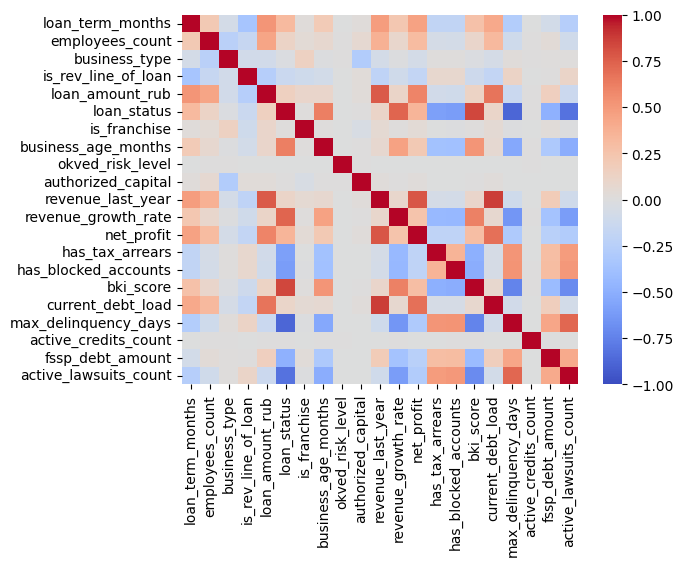

In [38]:
sns.heatmap(df.corr(numeric_only=True), cmap='coolwarm', vmin=-1, vmax=1)

In [39]:
df.to_csv('../data/feautred.csv')